Supply Chain Risk Detection Engine

Objectives

1. Detect inventory risks
2. Monitor supplier performance
3. Identify stockout threats
4. Prioritize corrective actions
5. Support executive decision making

In [5]:
## Imports

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

In [6]:
## Create Sample Dataset

risk_df = pd.DataFrame({

    "Item":[
        "Item A",
        "Item B",
        "Item C",
        "Item D",
        "Item E"
    ],

    "Current_Inventory":[
        100,
        500,
        75,
        400,
        50
    ],

    "Weekly_Demand":[
        80,
        50,
        70,
        30,
        60
    ],

    "Supplier_Fill_Rate":[
        95,
        98,
        85,
        99,
        80
    ]

})

display(risk_df)

,Item,Current_Inventory,Weekly_Demand,Supplier_Fill_Rate
0,Item A,100,80,95
1,Item B,500,50,98
2,Item C,75,70,85
3,Item D,400,30,99
4,Item E,50,60,80


In [7]:
## Calculate Weeks of Supply

risk_df["Weeks_of_Supply"] = (

    risk_df["Current_Inventory"]

    / risk_df["Weekly_Demand"]

)

display(risk_df)

,Item,Current_Inventory,Weekly_Demand,Supplier_Fill_Rate,Weeks_of_Supply
0,Item A,100,80,95,1.250000
1,Item B,500,50,98,10.000000
2,Item C,75,70,85,1.071429
3,Item D,400,30,99,13.333333
4,Item E,50,60,80,0.833333


In [8]:
## Identify Low Inventory Risk

risk_df["Inventory_Risk"] = np.where(

    risk_df["Weeks_of_Supply"] < 2,

    "High Risk",

    "Normal"

)

display(risk_df)

,Item,Current_Inventory,Weekly_Demand,Supplier_Fill_Rate,Weeks_of_Supply,Inventory_Risk
0,Item A,100,80,95,1.250000,High Risk
1,Item B,500,50,98,10.000000,Normal
2,Item C,75,70,85,1.071429,High Risk
3,Item D,400,30,99,13.333333,Normal
4,Item E,50,60,80,0.833333,High Risk


In [9]:
## Supplier Risk Category

risk_df["Supplier_Risk"] = np.where(

    risk_df["Supplier_Fill_Rate"] < 90,

    "High Risk",

    "Normal"

)

display(risk_df)

,Item,Current_Inventory,Weekly_Demand,Supplier_Fill_Rate,Weeks_of_Supply,Inventory_Risk,Supplier_Risk
0,Item A,100,80,95,1.250000,High Risk,Normal
1,Item B,500,50,98,10.000000,Normal,Normal
2,Item C,75,70,85,1.071429,High Risk,High Risk
3,Item D,400,30,99,13.333333,Normal,Normal
4,Item E,50,60,80,0.833333,High Risk,High Risk


In [10]:
## Overall Risk Score

risk_df["Risk_Score"] = (

    (risk_df["Weeks_of_Supply"] < 2).astype(int)

    +

    (risk_df["Supplier_Fill_Rate"] < 90).astype(int)

)

display(risk_df)

,Item,Current_Inventory,Weekly_Demand,Supplier_Fill_Rate,Weeks_of_Supply,Inventory_Risk,Supplier_Risk,Risk_Score
0,Item A,100,80,95,1.250000,High Risk,Normal,1
1,Item B,500,50,98,10.000000,Normal,Normal,0
2,Item C,75,70,85,1.071429,High Risk,High Risk,2
3,Item D,400,30,99,13.333333,Normal,Normal,0
4,Item E,50,60,80,0.833333,High Risk,High Risk,2


In [11]:
## Executive Risk Classification

risk_df["Overall_Risk"] = np.where(

    risk_df["Risk_Score"] >= 2,

    "Critical",

    np.where(

        risk_df["Risk_Score"] == 1,

        "Moderate",

        "Low"

    )

)

display(risk_df)

,Item,Current_Inventory,Weekly_Demand,Supplier_Fill_Rate,Weeks_of_Supply,Inventory_Risk,Supplier_Risk,Risk_Score,Overall_Risk
0,Item A,100,80,95,1.250000,High Risk,Normal,1,Moderate
1,Item B,500,50,98,10.000000,Normal,Normal,0,Low
2,Item C,75,70,85,1.071429,High Risk,High Risk,2,Critical
3,Item D,400,30,99,13.333333,Normal,Normal,0,Low
4,Item E,50,60,80,0.833333,High Risk,High Risk,2,Critical


In [12]:
## Risk Distribution

risk_df["Overall_Risk"].value_counts()

Overall_Risk
Low         2
Critical    2
Moderate    1
Name: count, dtype: int64

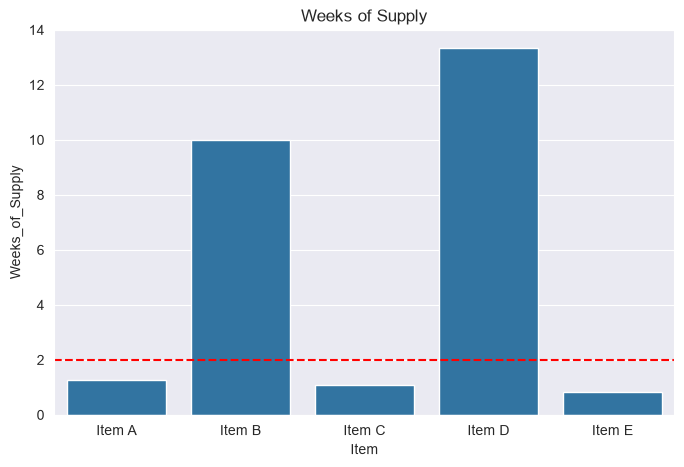

In [13]:
## Inventory Risk Visualization

plt.figure(figsize=(8,5))

sns.barplot(

    data=risk_df,

    x="Item",

    y="Weeks_of_Supply"

)

plt.axhline(

    y=2,

    color="red",

    linestyle="--"

)

plt.title("Weeks of Supply")

plt.show()

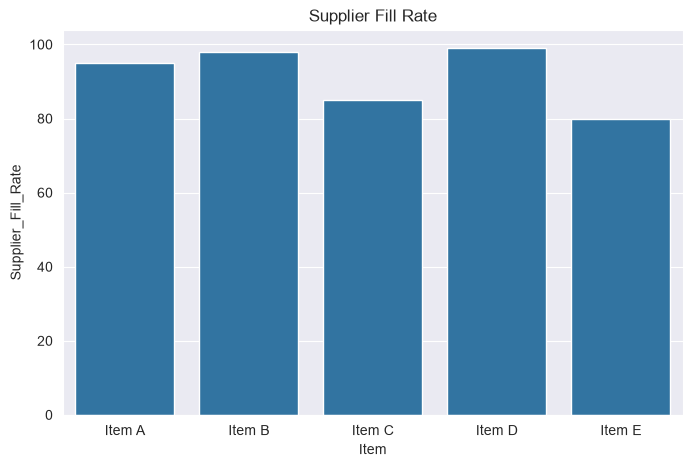

In [14]:
## Supplier Performance Chart

plt.figure(figsize=(8,5))

sns.barplot(

    data=risk_df,

    x="Item",

    y="Supplier_Fill_Rate"

)

plt.title("Supplier Fill Rate")

plt.show()

In [15]:
## Critical Items

critical_items = risk_df[

    risk_df["Overall_Risk"] == "Critical"

]

critical_items

,Item,Current_Inventory,Weekly_Demand,Supplier_Fill_Rate,Weeks_of_Supply,Inventory_Risk,Supplier_Risk,Risk_Score,Overall_Risk
2,Item C,75,70,85,1.071429,High Risk,High Risk,2,Critical
4,Item E,50,60,80,0.833333,High Risk,High Risk,2,Critical


In [16]:
## Executive Metrics

print("EXECUTIVE METRICS")

print()

print(

    "Total Items:",

    len(risk_df)

)

print(

    "Critical Risks:",

    (risk_df["Overall_Risk"] == "Critical").sum()

)

print(

    "Average Fill Rate:",

    round(

        risk_df["Supplier_Fill_Rate"].mean(),

        2

    )

)

print(

    "Average WOS:",

    round(

        risk_df["Weeks_of_Supply"].mean(),

        2

    )

)

EXECUTIVE METRICS

Total Items: 5
Critical Risks: 2
Average Fill Rate: 91.4
Average WOS: 5.3


In [17]:
## Recommended Actions

actions = [

    "Expedite critical inventory",

    "Review supplier performance",

    "Increase safety stock",

    "Improve forecast accuracy",

    "Monitor high-risk items daily"

]

for action in actions:

    print("-", action)

- Expedite critical inventory
- Review supplier performance
- Increase safety stock
- Improve forecast accuracy
- Monitor high-risk items daily


In [18]:
## Executive Scorecard

scorecard = risk_df[[

    "Item",

    "Current_Inventory",

    "Weekly_Demand",

    "Weeks_of_Supply",

    "Supplier_Fill_Rate",

    "Overall_Risk"

]]

display(scorecard)

,Item,Current_Inventory,Weekly_Demand,Weeks_of_Supply,Supplier_Fill_Rate,Overall_Risk
0,Item A,100,80,1.250000,95,Moderate
1,Item B,500,50,10.000000,98,Low
2,Item C,75,70,1.071429,85,Critical
3,Item D,400,30,13.333333,99,Low
4,Item E,50,60,0.833333,80,Critical


In [19]:
## Interview Talking Points

print("""

WALMART INTERVIEW TALKING POINTS

1. Low weeks of supply increases stockout risk.

2. Poor supplier performance drives
   availability issues.

3. Risk scoring helps prioritize action.

4. Executive dashboards improve visibility.

5. Early detection reduces operational cost.

""")



WALMART INTERVIEW TALKING POINTS

1. Low weeks of supply increases stockout risk.

2. Poor supplier performance drives
   availability issues.

3. Risk scoring helps prioritize action.

4. Executive dashboards improve visibility.

5. Early detection reduces operational cost.


